# EXP001_Baseline · Nhận diện biểu cảm trên FER2013

Thí nghiệm đo hiệu quả của CNN huấn luyện từ đầu trên ảnh xám 48 × 48. Chạy các ô theo thứ tự để xem lại kết quả đã lưu. Đặt `TRAIN_AGAIN = True` để huấn luyện một lượt mới bằng cấu hình YAML.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

project = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "BTL02")
               if (p / "configs/baseline.yaml").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from models.baseline_cnn import BaselineCNN
from evaluate import evaluate_checkpoint
from train import run_experiment, select_device

## Kiến trúc

Mỗi phép tích chập có kernel 3 × 3, stride 1 và padding 1. ReLU giữ nguyên kích thước tensor. Max pooling 2 × 2 giảm một nửa chiều cao và chiều rộng.

| Lớp | Kích thước đầu ra |
|---|---|
| Ảnh đầu vào | N × 1 × 48 × 48 |
| Conv1, ReLU | N × 32 × 48 × 48 |
| MaxPool1 | N × 32 × 24 × 24 |
| Conv2, ReLU | N × 64 × 24 × 24 |
| MaxPool2 | N × 64 × 12 × 12 |
| Conv3, ReLU | N × 128 × 12 × 12 |
| MaxPool3 | N × 128 × 6 × 6 |
| Flatten | N × 4608 |
| Linear, ReLU | N × 128 |
| Linear | N × 7 |

Bảy giá trị đầu ra là logits. `CrossEntropyLoss` nhận trực tiếp logits và nhãn `torch.long` từ 0 đến 6.

In [2]:
model = BaselineCNN()
print(model)
print(f"Số tham số có thể huấn luyện: {sum(p.numel() for p in model.parameters()):,}")

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4608, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=7, bias=True)
  )
)
Số tham số có thể huấn luyện: 683,527


## Dữ liệu, huấn luyện và quy tắc đánh giá

- **Training/validation.** Từ `train.csv`, dùng split phân tầng cố định seed 42: 80% train và 20% validation. Validation có nhãn nên dùng để theo dõi loss/accuracy và chọn checkpoint, kiến trúc, siêu tham số.
- **Huấn luyện.** Adam, learning rate 0,001, batch 64, 30 epoch. Mỗi lượt lưu checkpoint có validation loss thấp nhất cùng lịch sử theo epoch.
- **Test cuối cùng.** `test.csv` hiện chỉ có ảnh, không có nhãn. Chỉ sau khi chốt mô hình mới đánh giá test. Khi thiếu nhãn, cần đặt `data/fer2013.csv` vào thư mục `data/`; code sẽ kiểm tra ảnh và thứ tự trong `test.csv` có khớp với các ảnh PublicTest/PrivateTest trong file đó không.
- **Lệnh đánh giá test cuối cùng:** `python evaluate.py results/EXP001_Baseline/<run-timestamp>`. Nếu chưa có `fer2013.csv`, tiếp tục dùng validation; không gọi kết quả validation là test.

In [3]:
TRAIN_AGAIN = False
run = project / "results/EXP001_Baseline/20261120_122107_175923"
if TRAIN_AGAIN:
    run = run_experiment()

training = json.loads((run / "training.json").read_text(encoding="utf-8"))
history = pd.read_csv(run / "history.csv")
evaluation_path = run / "evaluation.json"
if evaluation_path.is_file():
    saved_evaluation = json.loads(evaluation_path.read_text(encoding="utf-8"))
else:
    saved_evaluation = None
if saved_evaluation is None or saved_evaluation.get("split") != "validation":
    validation_results = evaluate_checkpoint(
        run, project / "data", 64, select_device("auto"), split="validation"
    )
else:
    validation_results = saved_evaluation

print(f"Run: {run.name} | Thiết bị: {training['hardware']}")
print(f"Thời gian huấn luyện: {training['training_seconds']:.1f} giây")
print(f"Epoch tốt nhất theo validation loss: {training['best_epoch']}")
print(f"Validation: {validation_results['samples']} ảnh | "
      f"Accuracy: {validation_results['accuracy']:.2%} | "
      f"Macro F1: {validation_results['macro_f1']:.4f}")
display(history.loc[history.epoch == training["best_epoch"]])

Test accuracy 55.21% | Macro F1 0.4861
Run: 20261120_122107_175923 | Thiết bị: CPU
Thời gian huấn luyện: 1570.1 giây
Epoch tốt nhất theo validation loss: 8
Validation: 5742 ảnh | Accuracy: 55.21% | Macro F1: 0.4861


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
7,8,1.029917,0.613794,1.199502,0.552072


## Diễn biến theo epoch

Đường dọc đánh dấu epoch có validation loss thấp nhất. Accuracy là tỷ lệ nhãn dự đoán đúng. Đối chiếu hai đường loss để xem mô hình bắt đầu học quá khớp từ khi nào.

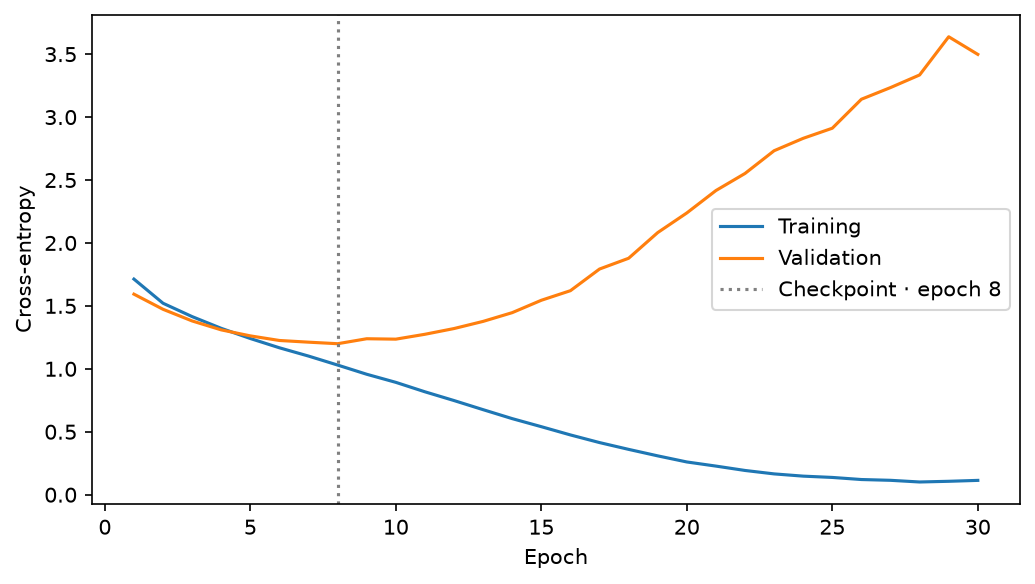

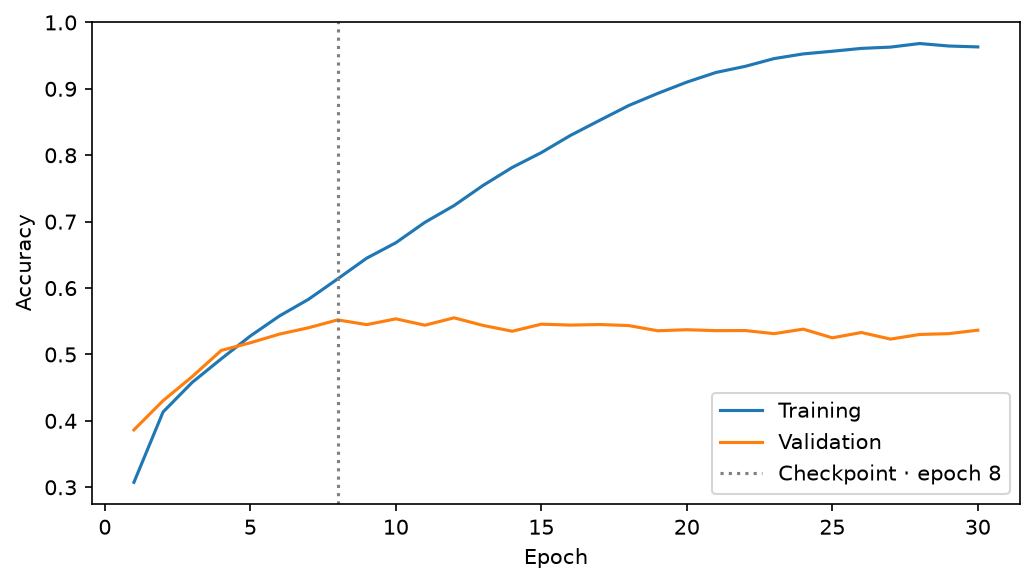

In [4]:
for name in ("loss", "accuracy"):
    display(Image(filename=str(run / f"{name}.png"), width=720))

## Đánh giá checkpoint trên validation

Các chỉ số dưới đây được tính trên 20% dữ liệu tách từ `train.csv`. Dùng chúng để so sánh thí nghiệm và chọn mô hình. Chúng không phải kết quả test.

,precision,recall,f1-score,support
Angry,0.5254,0.3755,0.4380,799.0
Disgust,0.4688,0.1724,0.2521,87.0
Fear,0.4361,0.2915,0.3494,820.0
Happy,0.6817,0.8281,0.7478,1443.0
Sad,0.4344,0.4596,0.4467,966.0
Surprise,0.6364,0.6735,0.6544,634.0
Neutral,0.4803,0.5539,0.5145,993.0


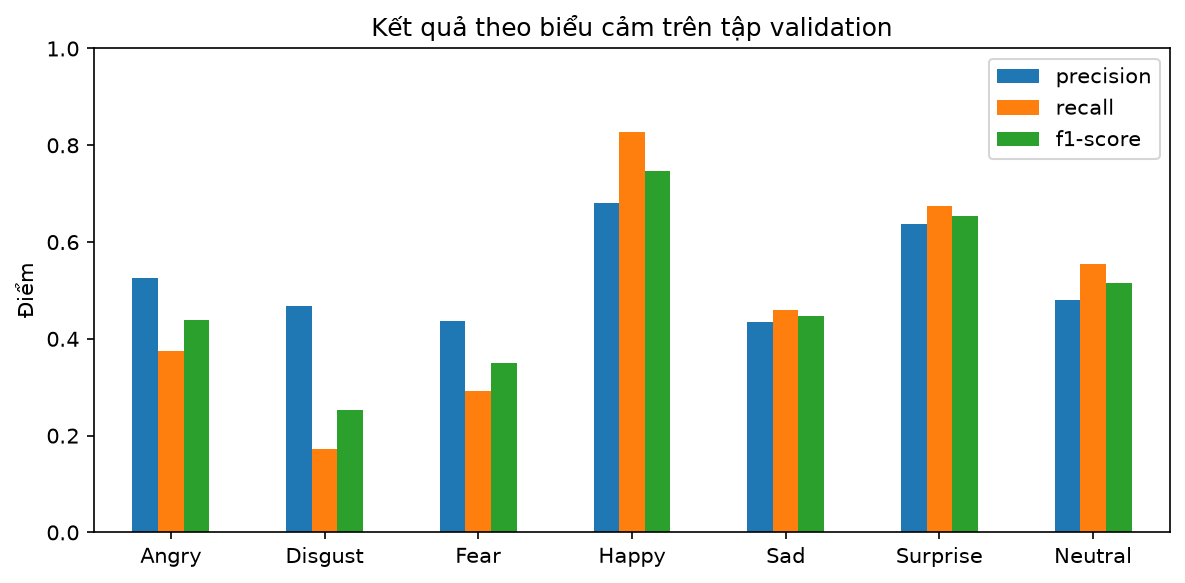

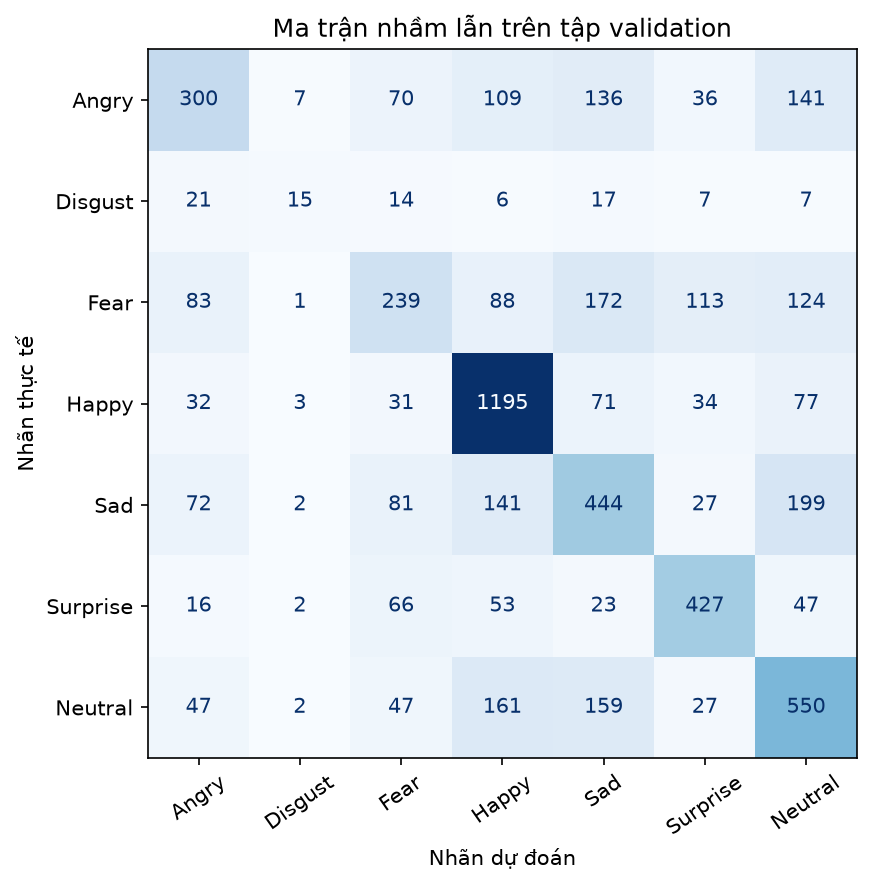

In [5]:
display(pd.DataFrame(validation_results["per_class"]).T.round(4))
for name in ("per_class", "confusion_matrix"):
    display(Image(filename=str(run / f"{name}.png"), width=720))

## Ví dụ dự đoán validation và bộ lọc đã học

Các ảnh đúng/sai bên dưới lấy từ validation. Hình cuối hiển thị các kernel của lớp tích chập đầu tiên, dùng cùng thang màu cho trọng số âm và dương.

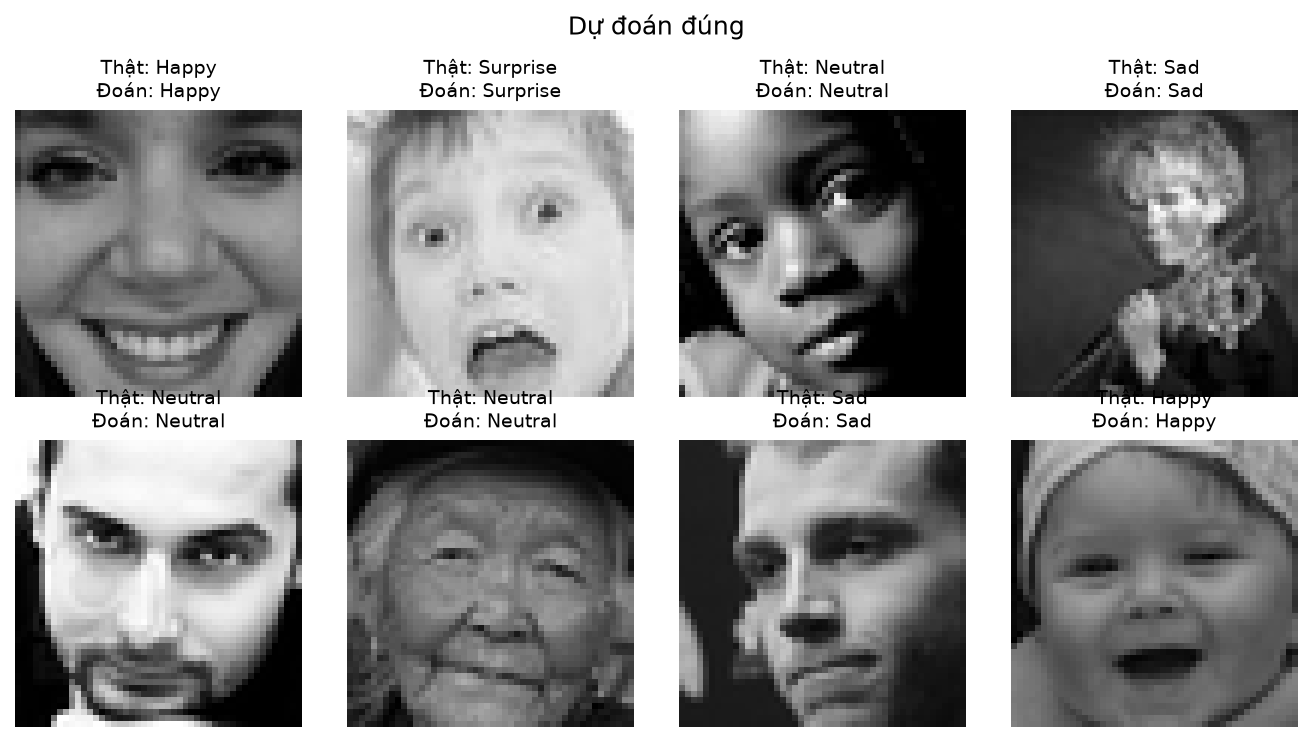

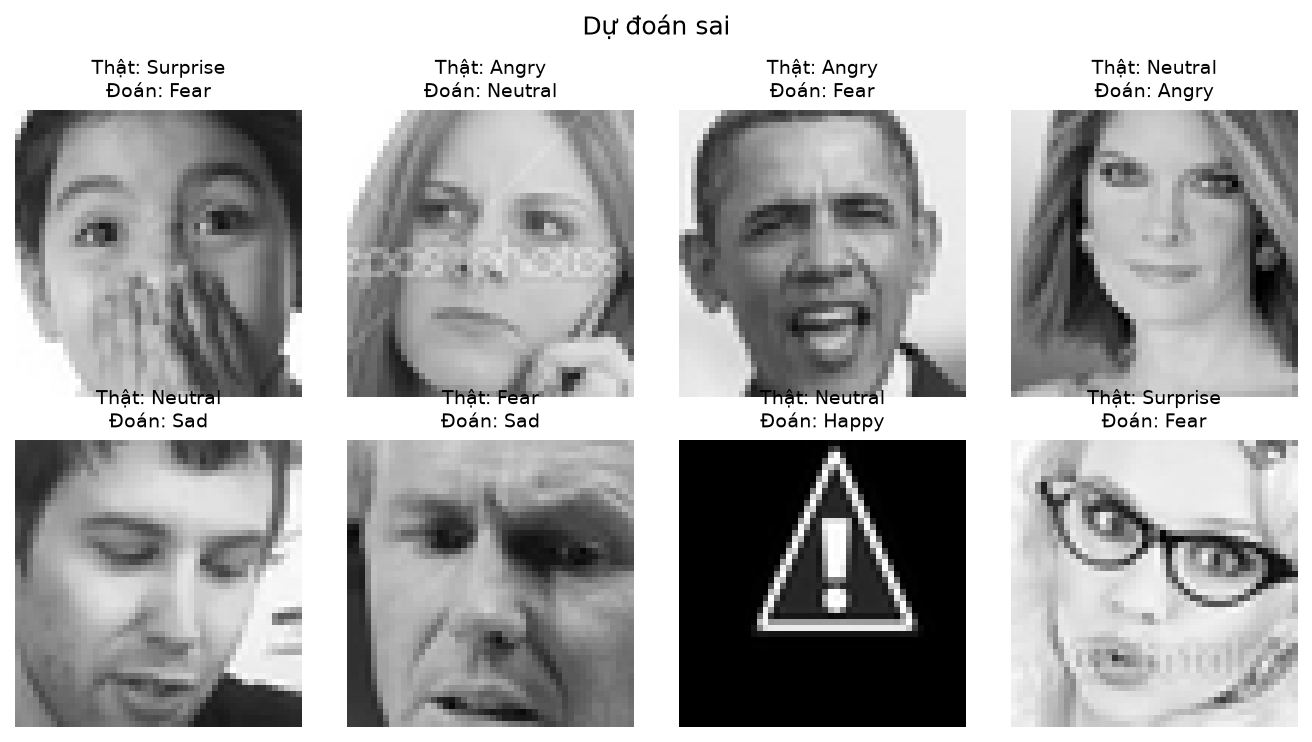

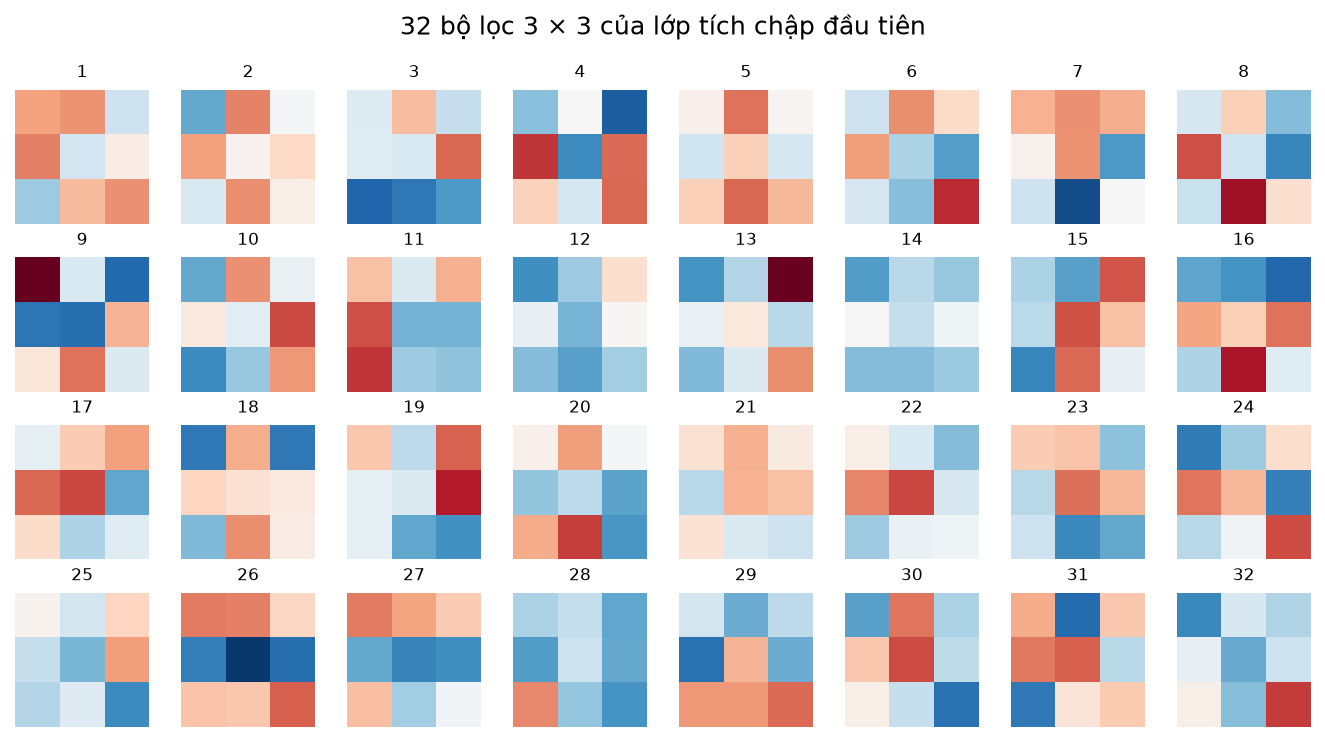

In [6]:
for name in ("correct", "incorrect", "conv1_filters"):
    display(Image(filename=str(run / f"{name}.png"), width=780))

## Quy trình cho các thí nghiệm tiếp theo

Giữ nguyên split, seed và cách tiền xử lý để so sánh công bằng. Thay đổi từng yếu tố kiến trúc hoặc siêu tham số, chọn mô hình dựa trên validation, rồi mới đánh giá test một lần cho mô hình cuối. Muốn đánh giá test, cần `data/fer2013.csv` có nhãn và ảnh khớp với `test.csv`; chạy lệnh ở phần trên. Không cần xóa các thư mục `results` cũ: mỗi lượt chạy nằm trong thư mục riêng và có thể dùng làm lịch sử so sánh.